# W12A 실습 B · CF·MF 하이브리드 추천

**딥러닝응용I(추천시스템) 01 · 2026-11-17 · 교재 10.1–10.3 및 연습 10-1**

예측이 한쪽은 높고 한쪽은 낮으면 어느 비중에서 상쇄될까요? 실제 점수 4, CF 3, MF 5를 먼저 계산해 보세요. 0은 CF만, 1은 MF만입니다.

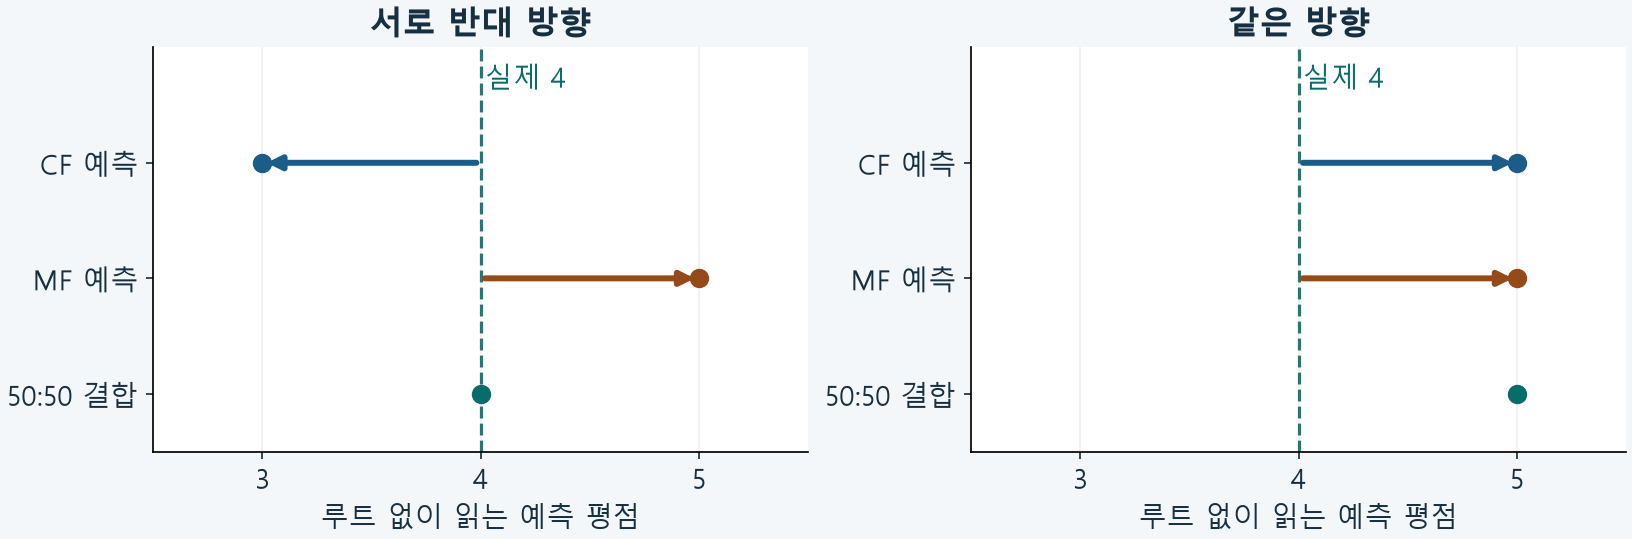


[Figure source](https://raw.githubusercontent.com/lunalab-ai/recommender/2026-fall-w12a/course/notion/assets/w12a/06-errors.png)


In [ ]:
import os
import sys
import subprocess
from pathlib import Path
from time import perf_counter
from IPython.display import display

TAG = "2026-fall-w12a"
IN_COLAB = "google.colab" in sys.modules
os.environ.update(CUDA_VISIBLE_DEVICES="-1", TF_CPP_MIN_LOG_LEVEL="2",
                  TF_ENABLE_ONEDNN_OPTS="0", GRADIO_ANALYTICS_ENABLED="False")
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    f"luna-recommender-course[apps,neural] @ git+https://github.com/lunalab-ai/recommender.git@{TAG}",
                    "gradio==6.31.0"], check=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from luna_recsys.hybrid_lab import (
    PAIR, temporal_split, load_ratings, fit_predictors, predict_pair_tables,
    rmse, model_report, pick_catalog, fit_deep_scores,
)
from luna_recsys.hybrid_app import HybridDashboard, build_dashboard

CACHE = Path(os.environ.get("LUNA_W12A_CACHE", Path.home() / ".cache/luna-recsys/w12a"))


### 10.1–10.2 · 점수 열을 가중평균하는 한 줄

끝점 0과 1을 손으로 계산하고, MF 지분 0.8을 넣으세요. 아래 공식에서 점수에 곱하는 부분을 본문에 찾아 표시하세요.

$$
\widehat r_{\mathrm{mix}} = w\,\widehat r_{\mathrm{MF}} + (1-w)\,\widehat r_{\mathrm{CF}}
$$

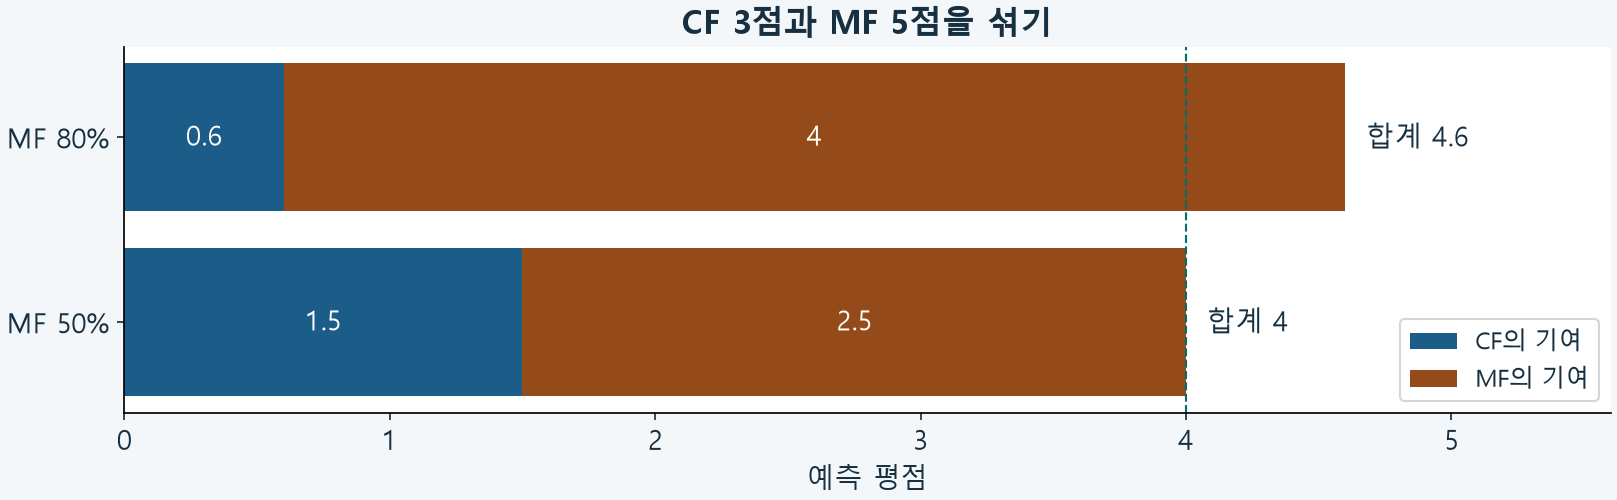


[Figure source](https://raw.githubusercontent.com/lunalab-ai/recommender/2026-fall-w12a/course/notion/assets/w12a/07-weight.png)


In [ ]:
def blend_scores(rows, weight_mf):
    """Same-scale rating prediction: one MF share and its CF complement."""
    if not 0 <= weight_mf <= 1:
        raise ValueError("MF share must be between 0 and 1.")
    cf = rows["score_cf"].to_numpy(float)
    mf = rows["score_mf"].to_numpy(float)
    if not (np.isfinite(cf).all() and np.isfinite(mf).all()):
        raise ValueError("Blend requires two finite scores on each row.")
    return weight_mf * mf + (1 - weight_mf) * cf


In [ ]:
toy = pd.DataFrame({"score_cf": [3., 5.], "score_mf": [5., 5.], "rating": [4., 4.]})
toy["half"] = blend_scores(toy, .5)
toy["book_share"] = blend_scores(toy, .8)
display(toy)
print("양쪽 평균 RMSE", (rmse(toy.rating, toy.score_cf)+rmse(toy.rating, toy.score_mf))/2)
print("50:50 RMSE", rmse(toy.rating, toy.half))


### 10.3 · 섞인 행에서 같은 영화 찾기

아래의 잘못된 나란히 붙이기 방식에서 영화 2의 MF 예측이 영화 1에 들어갑니다. 고친 쿼리는 사용자와 영화 ID 두 열을 함께 사용해야 합니다. 아래 본문 함수를 읽고, 공통 키가 없는 행 하나를 추가해 어느 검사에서 멈추는지 확인하세요.

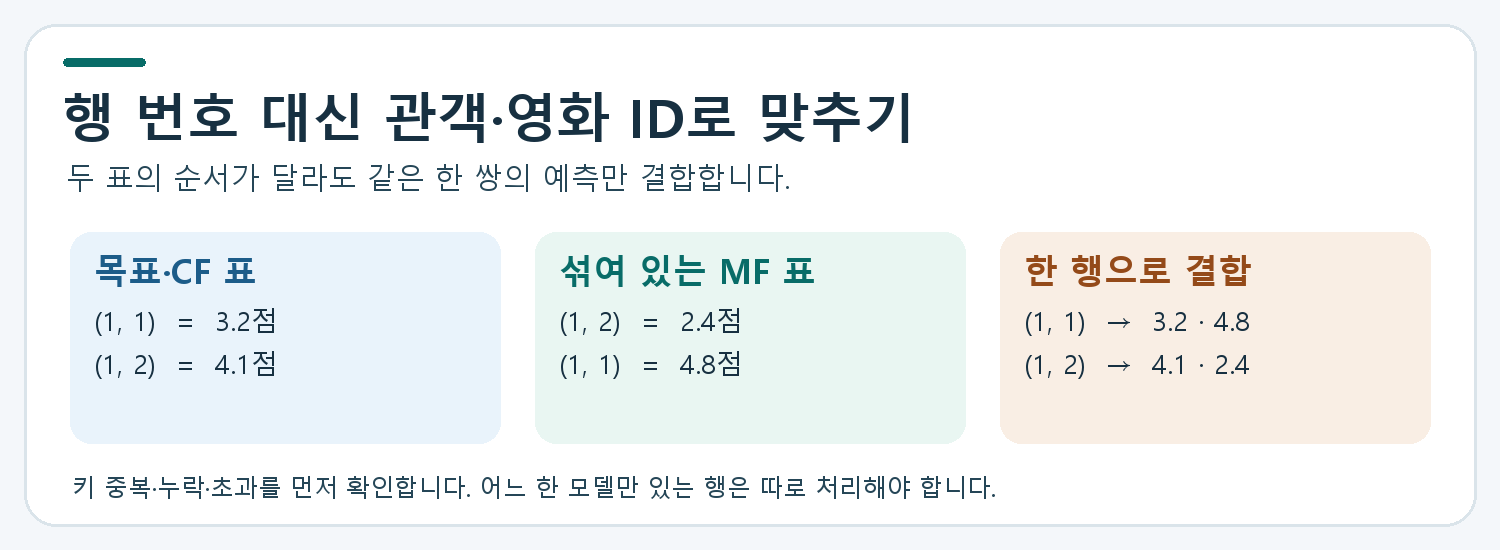


[Figure source](https://raw.githubusercontent.com/lunalab-ai/recommender/2026-fall-w12a/course/notion/assets/w12a/08-join.png)


In [ ]:
def align_predictions(base, cf, mf):
    """Refuse duplicates, missing and extra keys before merging by ID."""
    for frame in (base, cf, mf):
        if frame[PAIR].isna().any().any() or frame.duplicated(PAIR).any():
            raise ValueError("A user–movie key must be present and unique.")
    expected = set(base[PAIR].itertuples(index=False, name=None))
    for frame in (cf, mf):
        actual = set(frame[PAIR].itertuples(index=False, name=None))
        if actual != expected:
            raise ValueError(f"Keys differ: {len(expected-actual)} missing / {len(actual-expected)} extra.")
    return base.merge(cf, on=PAIR, how="left", validate="one_to_one").merge(
        mf, on=PAIR, how="left", validate="one_to_one"
    )


In [ ]:
left = pd.DataFrame({"user_id": [1, 1], "movie_id": [1, 2], "rating": [5, 3]})
cf_toy = left[PAIR].assign(score_cf=[3.2, 4.1])
mf_toy = left[PAIR].assign(score_mf=[4.8, 2.4]).iloc[::-1]
display(left.assign(misplaced_mf=mf_toy.score_mf.to_numpy()))
display(align_predictions(left, cf_toy, mf_toy))


### 실제 CF·MF · 과거에서 학습하고 다음 기간에서 선택하기

GroupLens의 MovieLens 100K 전체 평점으로 시간순 분할합니다. CF는 37 이웃까지, MF는 편향과 잠재요인을 학습합니다. 공통 척도는 1–5점입니다. 충분한 CF 이웃 또는 MF의 훈련 ID가 없으면 두 모델 모두 훈련 전체 평균을 씁니다. 적용률도 확인하세요.

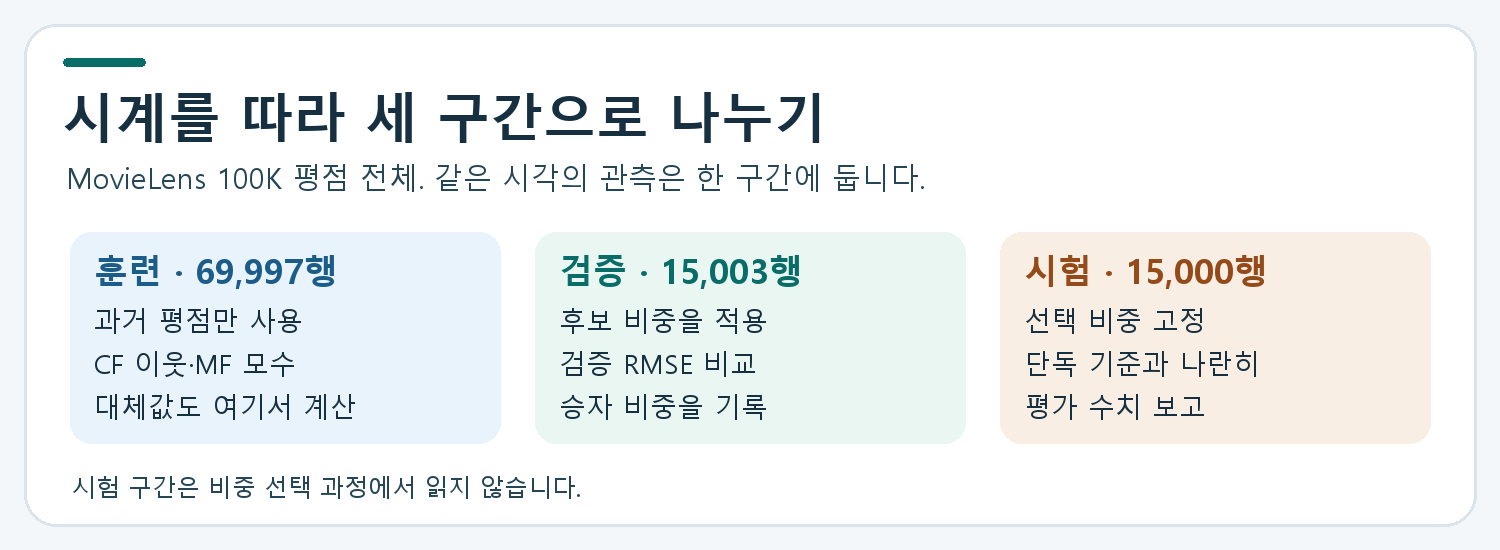


[Figure source](https://raw.githubusercontent.com/lunalab-ai/recommender/2026-fall-w12a/course/notion/assets/w12a/09-time.png)


In [ ]:
start = perf_counter()
movie_data = load_ratings(CACHE / "movielens")
parts = temporal_split(movie_data.ratings)
assert parts["train"].timestamp.max() < parts["validation"].timestamp.min()
assert parts["validation"].timestamp.max() < parts["test"].timestamp.min()
cf, mf = fit_predictors(parts["train"])
valid_labels = parts["validation"][PAIR + ["rating"]]
cf_valid, mf_valid = predict_pair_tables(cf, mf, valid_labels[PAIR])
valid = align_predictions(valid_labels, cf_valid, mf_valid.sample(frac=1, random_state=17))
print("행 수", {k: len(v) for k, v in parts.items()}, "준비/학습/검증 점수 초", round(perf_counter()-start, 2))
print("대체 전 검증 적용률", valid[["supported_cf", "supported_mf"]].mean().to_dict())


### 검증에서 비중 선택 · 한 변경에 한 번 비교하기

grid를 0%, 25%, 50%, 75%, 100%만 보게 직접 고쳐 촘촘한 원래 grid와 비교하세요. 시험 평점을 넣기 전에 결과와 이유를 기록하세요. 본문 함수에서 달라진 비중을 앱으로 연결합니다.


In [ ]:
def select_weight(validation, grid=None, *, blend_fn=blend_scores):
    """Score only validation labels. Break exact ties toward lower MF share."""
    if grid is None:
        grid = np.linspace(0, 1, 101)
    curve = pd.DataFrame([
        (float(weight), rmse(validation.rating, blend_fn(validation, weight)))
        for weight in grid
    ], columns=["weight_mf", "validation_rmse"])
    best = curve.sort_values(["validation_rmse", "weight_mf"]).iloc[0]
    return float(best.weight_mf), curve


In [ ]:
weight, curve = select_weight(valid, blend_fn=blend_scores)
display(curve[curve.weight_mf.isin([0, .8, 1, weight])])
print("검증으로 고정한 MF 지분", weight)
ax = curve.plot(x="weight_mf", y="validation_rmse", legend=False, color="#176a97", figsize=(7, 3))
ax.axvline(weight, color="#b44415", linestyle="--")
ax.set(xlabel="MF weight", ylabel="Validation RMSE")
plt.show()


### 결과 확인 · 고정한 비중으로 시험 한 번 평가

최적 비중을 기록하고 이 셀을 실행하세요. 결과를 보고 비중을 다시 고르면 시험이 선택용 자료가 됩니다. 시험의 RMSE는 실제 선호 평점에 대한 오차입니다. 앱의 Top-3는 한 관객에서 어떤 영화가 먼저 보이는지 보여 줍니다.


In [ ]:
test_labels = parts["test"][PAIR + ["rating"]]
cf_test, mf_test = predict_pair_tables(cf, mf, test_labels[PAIR])
test = align_predictions(test_labels, cf_test, mf_test)
assert np.allclose(blend_scores(test, 0), test.score_cf)
assert np.allclose(blend_scores(test, 1), test.score_mf)
display(model_report(test, weight, blend_fn=blend_scores))
print("대체 전 시험 적용률", test[["supported_cf", "supported_mf"]].mean().to_dict())


### 앱 · 순위가 바뀌는 비중을 찾으세요

후보 점수선 두 개가 교차하는 지점 앞뒤를 살펴봅니다. 화면의 Top-3와 CSV가 같은지 확인하세요. 도함수 대신 두 영화의 점수 차가 0이 되는 비중을 손으로 풀 수도 있습니다.

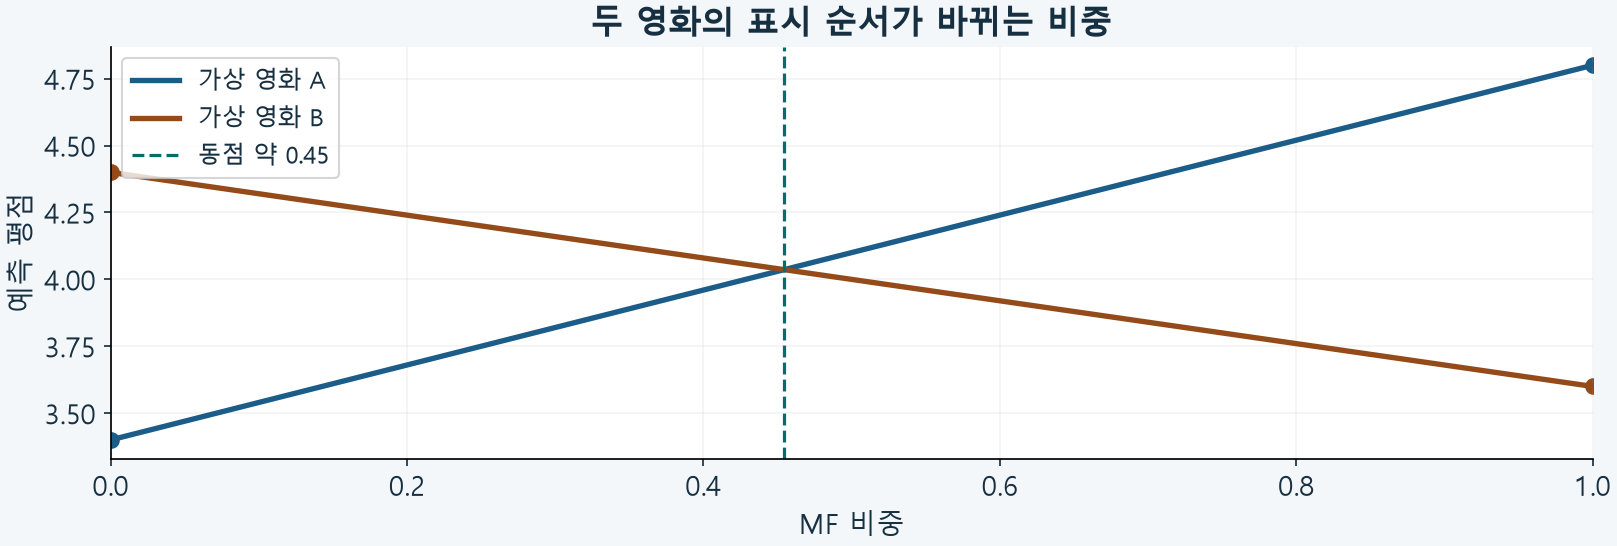


[Figure source](https://raw.githubusercontent.com/lunalab-ai/recommender/2026-fall-w12a/course/notion/assets/w12a/11-cross.png)


In [ ]:
candidates = pick_catalog(parts["train"], movie_data.movies, cf, mf, align_fn=align_predictions)
dashboard = HybridDashboard(candidates, curve, weight, blend_fn=blend_scores)
for preview in (0, weight, 1):
    print("MF 지분", preview)
    display(dashboard.current(preview))
display(dashboard.transitions_plot(weight))
csv_path = dashboard.export(weight)
actual = pd.read_csv(csv_path)
assert actual.movie_id.tolist() == dashboard.current(weight).movie_id.tolist()


**Colab 안에서 슬라이더를 사용하세요.** 화면이 뜨기 어려우면 위 셀의 preview 값을 직접 바꿔 표와 CSV를 비교할 수 있습니다. Gradio 객체는 같은 본문 함수와 CSV를 씁니다. 외부 공개 주소는 생성하지 않습니다.


In [ ]:
from ipywidgets import FloatSlider, VBox, Output, Button
from IPython.display import clear_output, FileLink

slider = FloatSlider(value=weight, min=0, max=1, step=.01, description="MF 지분")
area = Output()
save = Button(description="현재 Top-3 CSV")

def update_preview(_=None):
    with area:
        clear_output(wait=True)
        display(dashboard.current(slider.value))
        for plot in [dashboard.validation_plot, dashboard.transitions_plot]:
            figure = plot(slider.value)
            display(figure)
            plt.close(figure)

def offer_csv(_):
    with area:
        path = Path(dashboard.export(slider.value))
        target = Path("w12a-current-top3.csv")
        target.write_bytes(path.read_bytes())
        if IN_COLAB:
            from google.colab import files
            files.download(str(target))
        else:
            display(FileLink(str(target)))

slider.observe(update_preview, names="value")
save.on_click(offer_csv)
if IN_COLAB:
    from google.colab import output
    output.enable_custom_widget_manager()
display(VBox([slider, save, area]))
update_preview()
gradio_app = build_dashboard(dashboard)


### 연습 10-1 · CF 자리를 딥러닝 평점으로 바꾸기

이전에 구현한 사용자·영화 임베딩과 작은 MLP를 활용합니다. 동일한 train과 평점 척도, 동일한 검증/시험 행을 씁니다. 딥러닝 결과로 대체할 열과 결합식은 다음 셀에서 직접 찾을 수 있습니다. 두 비중은 각각 따로 고릅니다.

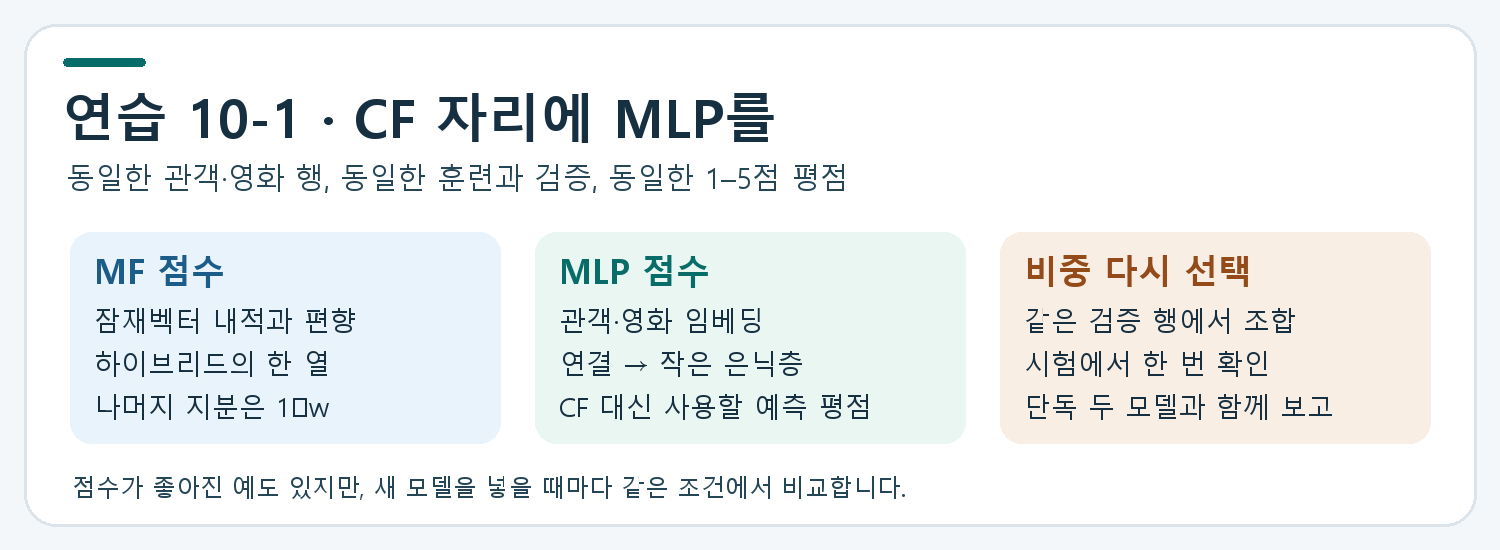


[Figure source](https://raw.githubusercontent.com/lunalab-ai/recommender/2026-fall-w12a/course/notion/assets/w12a/12-neural.png)


In [ ]:
mlp_valid, mlp_test = fit_deep_scores(parts["train"], valid_labels[PAIR], test_labels[PAIR])
deep_validation = align_predictions(valid_labels, mlp_valid, mf_valid)
deep_weight, deep_curve = select_weight(deep_validation, blend_fn=blend_scores)
print("MLP와 결합할 MF 지분", deep_weight)
deep_test = align_predictions(test_labels, mlp_test, mf_test)
display(model_report(deep_test, deep_weight, blend_fn=blend_scores, other_name="MLP"))
print("W12A_B_RUN_ALL_OK")


In [ ]:
assert len(movie_data.ratings) == 100_000 and len(parts["test"]) == 15_000
assert weight == float(curve.sort_values(["validation_rmse", "weight_mf"]).iloc[0].weight_mf)
assert dashboard.current(0).movie_id.tolist() != dashboard.current(1).movie_id.tolist()
assert np.allclose(actual.combined, dashboard.current(weight).combined)
assert not set(valid[PAIR].itertuples(index=False, name=None)).intersection(
    test[PAIR].itertuples(index=False, name=None)
)
assert len(deep_test) == len(test) and 0 <= deep_weight <= 1
print("W12A_B_RUNTIME_CHECKS_PASSED")
